# Ejercicio 2: prueba de hipótesis para una media

Un fabricante de cables de acero asegura que la tensión media que soportan es de 8000 kg/cm². Dada la importancia de que se cumpla esa especificación, antes de una compra se realizó un ensayo de las tensiones de ruptura de 6 cables producidos por esa industria. La tensión media observada fue de 7750 kg/cm² y el desvío estándar muestral fue de 145 kg/cm².

¿Es posible aceptar lo afirmado por el fabricante y comprar dichos cables, a un nivel de significación del 1%?

## Planteamiento

CUIDADO! no es resolver es poder tomar una decision!!! La decisión de compra es aceptar los cables si la tensión media es igual o mayor que 8000 kg/cm². Por lo tanto, la hipótesis alternativa representa el riesgo que se quiere detectar: que la tensión media sea menor que 8000 kg/cm².

- **H0:** μ ≥ 8000 kg/cm²
- **H1:** μ < 8000 kg/cm²
- **n:** 6
- **x̄:** 7750 kg/cm²
- **s:** 145 kg/cm²
- **α:** 0.01

Como la muestra es pequeña y no se conoce la desviación estándar poblacional, se utiliza una prueba t de Student para una media, con 5 grados de libertad. Es una prueba unilateral a la izquierda: toda la región crítica del 1% se encuentra en la cola izquierda.


Media de referencia bajo H0 (mu0): 8000 kg/cm²
Media muestral (x̄): 7750 kg/cm²
Desviación estándar muestral (s): 145 kg/cm²
Tamaño de muestra (n): 6
Grados de libertad: 5
Estadístico t calculado: -4.2233
Valor p: 0.0042
Valor crítico inferior: -3.3649
Decisión: se rechaza H0.
Conclusión: no es posible aceptar la afirmación del fabricante ni comprar los cables al 1%.


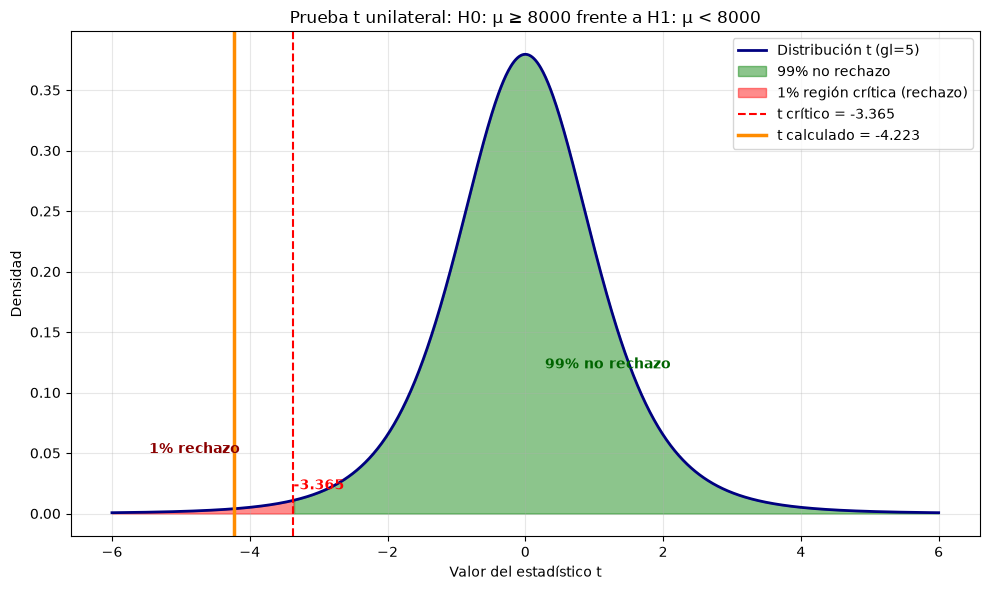

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Datos del problema
mu0 = 8000
x_barra = 7750
s = 145
n = 6
alpha = 0.01

# Hipótesis: H0: mu >= 8000 frente a H1: mu < 8000
gl = n - 1
T = (x_barra - mu0) / (s / np.sqrt(n))
p_valor = stats.t.cdf(T, df=gl)
critico = stats.t.ppf(alpha, df=gl)

print(f"Media de referencia bajo H0 (mu0): {mu0} kg/cm²")
print(f"Media muestral (x̄): {x_barra} kg/cm²")
print(f"Desviación estándar muestral (s): {s} kg/cm²")
print(f"Tamaño de muestra (n): {n}")
print(f"Grados de libertad: {gl}")
print(f"Estadístico t calculado: {T:.4f}")
print(f"Valor p: {p_valor:.4f}")
print(f"Valor crítico inferior: {critico:.4f}")

if p_valor < alpha:
    print("Decisión: se rechaza H0.")
    print("Conclusión: no es posible aceptar la afirmación del fabricante ni comprar los cables al 1%.")
else:
    print("Decisión: no se rechaza H0.")
    print("Conclusión: es posible aceptar la afirmación del fabricante y comprar los cables al 1%.")

# Distribución t y regiones de la prueba unilateral izquierda
x = np.linspace(-6, 6, 1000)
y = stats.t.pdf(x, df=gl)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x, y, color="navy", linewidth=2, label=f"Distribución t (gl={gl})")

# Región de no rechazo: 99%
region_no_rechazo = x >= critico
ax.fill_between(
    x, y, where=region_no_rechazo,
    color="green", alpha=0.45,
    label="99% no rechazo"
)

# Región crítica: 1% en la cola izquierda
region_critica = x <= critico
ax.fill_between(
    x, y, where=region_critica,
    color="red", alpha=0.45,
    label="1% región crítica (rechazo)"
)

# Límite crítico y estadístico calculado
ax.axvline(
    critico, color="red", linestyle="--", linewidth=1.5,
    label=f"t crítico = {critico:.3f}"
)
ax.axvline(
    T, color="darkorange", linewidth=2.5,
    label=f"t calculado = {T:.3f}"
)

# Etiquetas de las regiones
ax.text(-4.8, 0.05, "1% rechazo", ha="center", color="darkred", fontweight="bold")
ax.text(1.2, 0.12, "99% no rechazo", ha="center", color="darkgreen", fontweight="bold")
ax.text(critico, 0.02, f"{critico:.3f}", color="red", ha="left", fontweight="bold")

ax.set_title("Prueba t unilateral: H0: μ ≥ 8000 frente a H1: μ < 8000")
ax.set_xlabel("Valor del estadístico t")
ax.set_ylabel("Densidad")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()
